# Computational checks for Bayesian subspace tracking

The [beamforming](01_array.ipynb) and [contact-normal](03_contact.ipynb) notebooks explain the applications. This supplement follows the computational chain behind them: normalized likelihood, information, finite-data curvature, tracking envelope, prediction, block EM, and reliability under changed noise or motion.

Figure IDs follow the implementation guide. The [claim manifest](../results/implementation_audit/claim_manifest.json) maps each requested check to its routine, metric, figure, assumptions and observed status. Exact aliases of main figures are identified in the figure manifest; an alias is not another independent experiment. The [audit note](../docs/implementation_guide_audit.md) identifies which requirements existed and which were added, including unavailable manuscript-source checks.

The guide names `main.tex` and `supplementary.tex`, which were not present in the supplied checkout. Explicit formulas in the guide and the supplied draft are the available specification; no claim of inspecting missing source text is made. Negative, inconclusive and numerically unresolved results remain in the [findings](../results/implementation_audit/findings.md) and raw tables.

In [1]:
from pathlib import Path
import sys, json, hashlib
from IPython.display import Image, Markdown, display
ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from scripts.make_implementation_audit_notebook import verify_audit
from lib.plotting import plt
FIG = verify_audit()
BASE = ROOT / 'results/implementation_audit'
F = BASE / 'paper/figures'
assert plt.rcParams['text.usetex'] is True
assert plt.rcParams['figure.dpi'] == plt.rcParams['savefig.dpi'] == 200

def show(name):
    path = F / (name + '.png')
    assert hashlib.sha256(path.read_bytes()).hexdigest() == FIG['files'][path.name]
    display(Image(filename=str(path), width=1400))
    display(Markdown(FIG['captions'][name]))

print('Verified the current general gate, completed studies and final paper figures.')

Verified the current general gate, completed studies and final paper figures.


## B2a; C2. From a likelihood to expected information

The real marginal model has $F=L(\tau^2)^2/[s(s+\tau^2)]I$. Proper-complex data double this coefficient in real/imaginary tangent coordinates and double the tangent dimension. The conditional calculation uses recorded inputs; it does not reconstruct an unobserved input from a measured response.

The first panel compares analytical information with empirical score covariance. The second checks expected likelihood Hessians and exact Gaussian KL curvature at several finite-difference steps. The third compares the KL contours and their local Fisher approximation in the same tangent chart. Discounted Hessians use weights $w_j$, whereas discounted score covariance uses $w_j^2$; those separate tests remain in the tables.

In [2]:
import numpy as np
from lib.beamforming_theory import passive_fisher_information
F_real = passive_fisher_information(3, 1, s=0.2, q=1.3, observations=4, complex_data=False)
F_complex = passive_fisher_information(3, 1, s=0.2, q=1.3, observations=4, complex_data=True)
assert F_complex.shape[0] == 2 * F_real.shape[0]
assert np.allclose(np.diag(F_complex), 2 * F_real[0, 0])
print('Real tangent dimension:', len(F_real), '; complex real-coordinate dimension:', len(F_complex))
print('Fisher coefficient:', F_real[0, 0], '(real),', F_complex[0, 0], '(proper complex)')

Real tangent dimension: 2 ; complex real-coordinate dimension: 4
Fisher coefficient: 22.53333333333333 (real), 45.06666666666666 (proper complex)


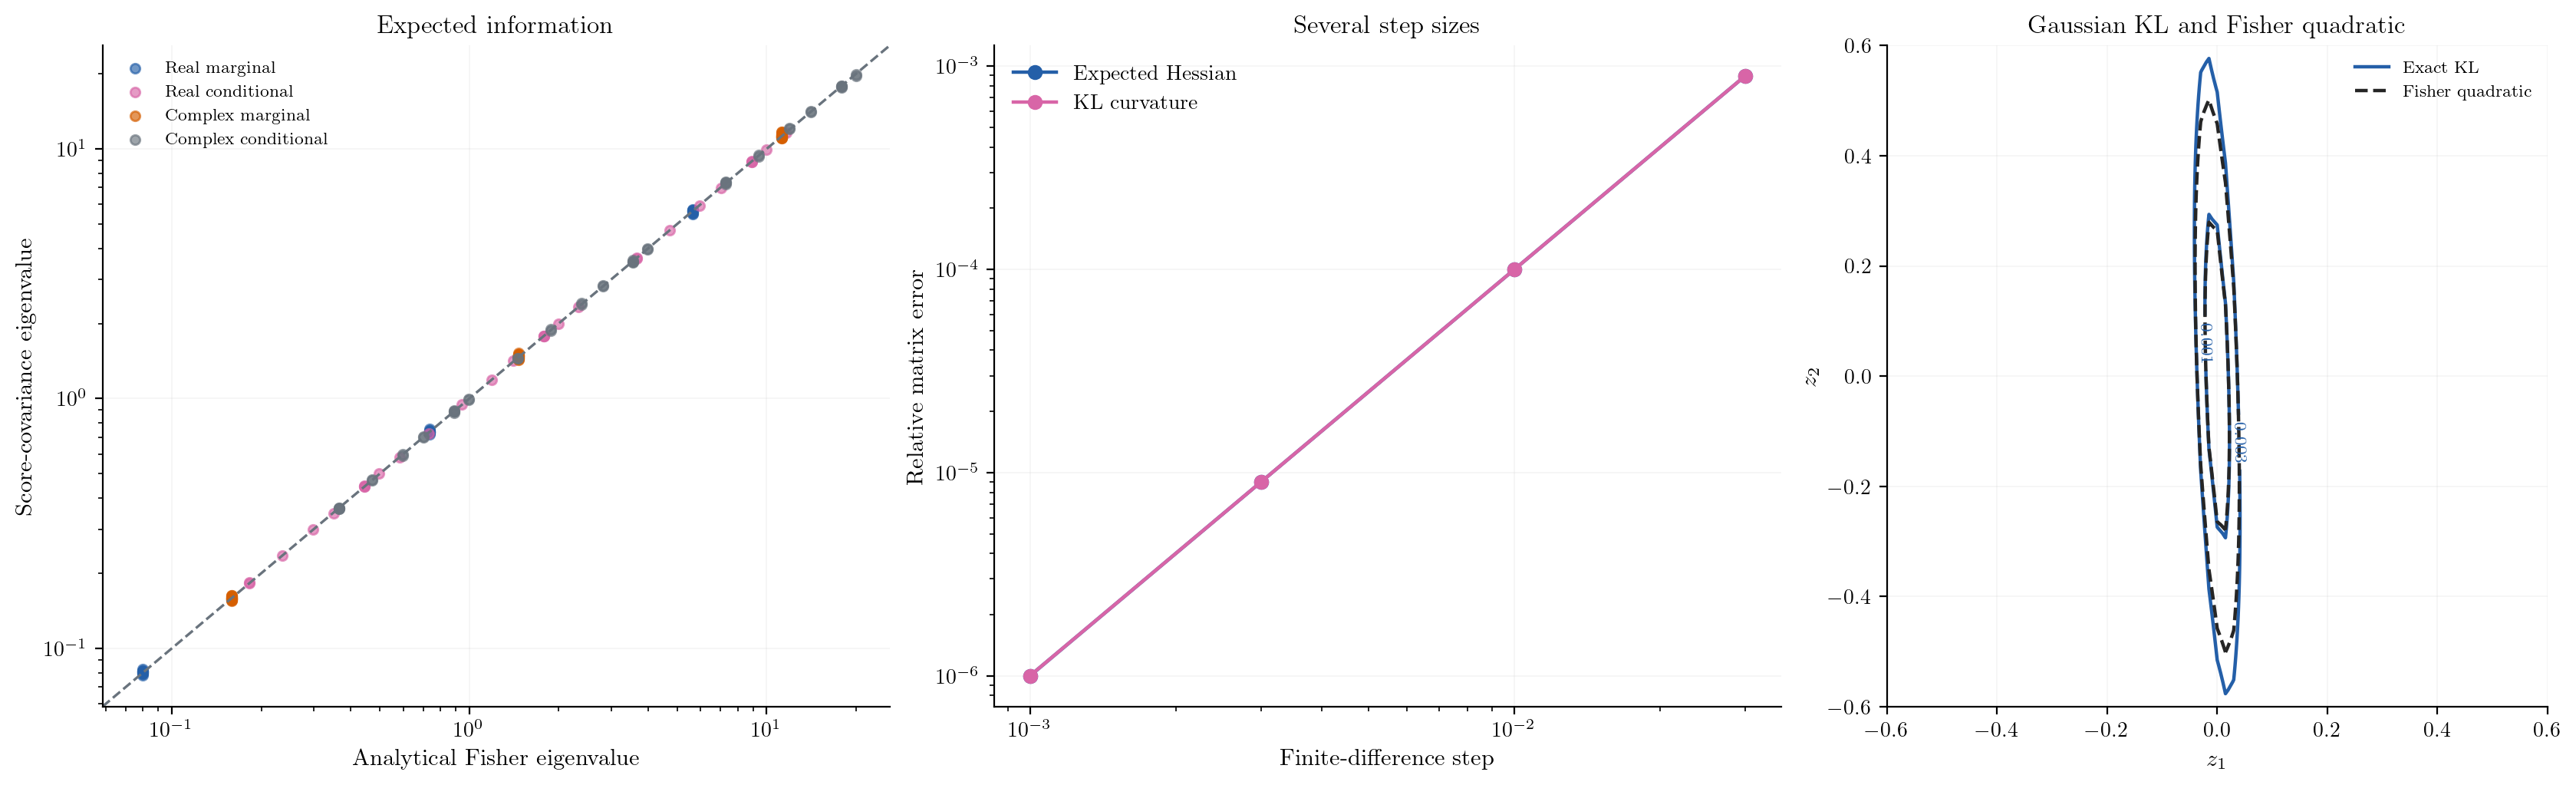

Fisher eigenvalues use aligned tangent coordinates and directly recorded inputs for the conditional law. Finite-difference bands show the range across the declared cases, not confidence intervals. Exact Gaussian KL contours and the Fisher quadratic use the same displayed levels and tangent coordinates.

In [3]:
show('B2a_C2_information')

## B2a. Check observation count and signal-to-noise ratio separately

The next panel uses a separate declared cohort. Each episode sums its likelihood scores over $L$ independent observations; empirical covariance is then estimated across independent episodes. The reference Fisher matrix scales with $L$. A Monte Carlo draw count is not relabeled as an observation count, and posterior-curvature samples are not used as substitutes for expected information.

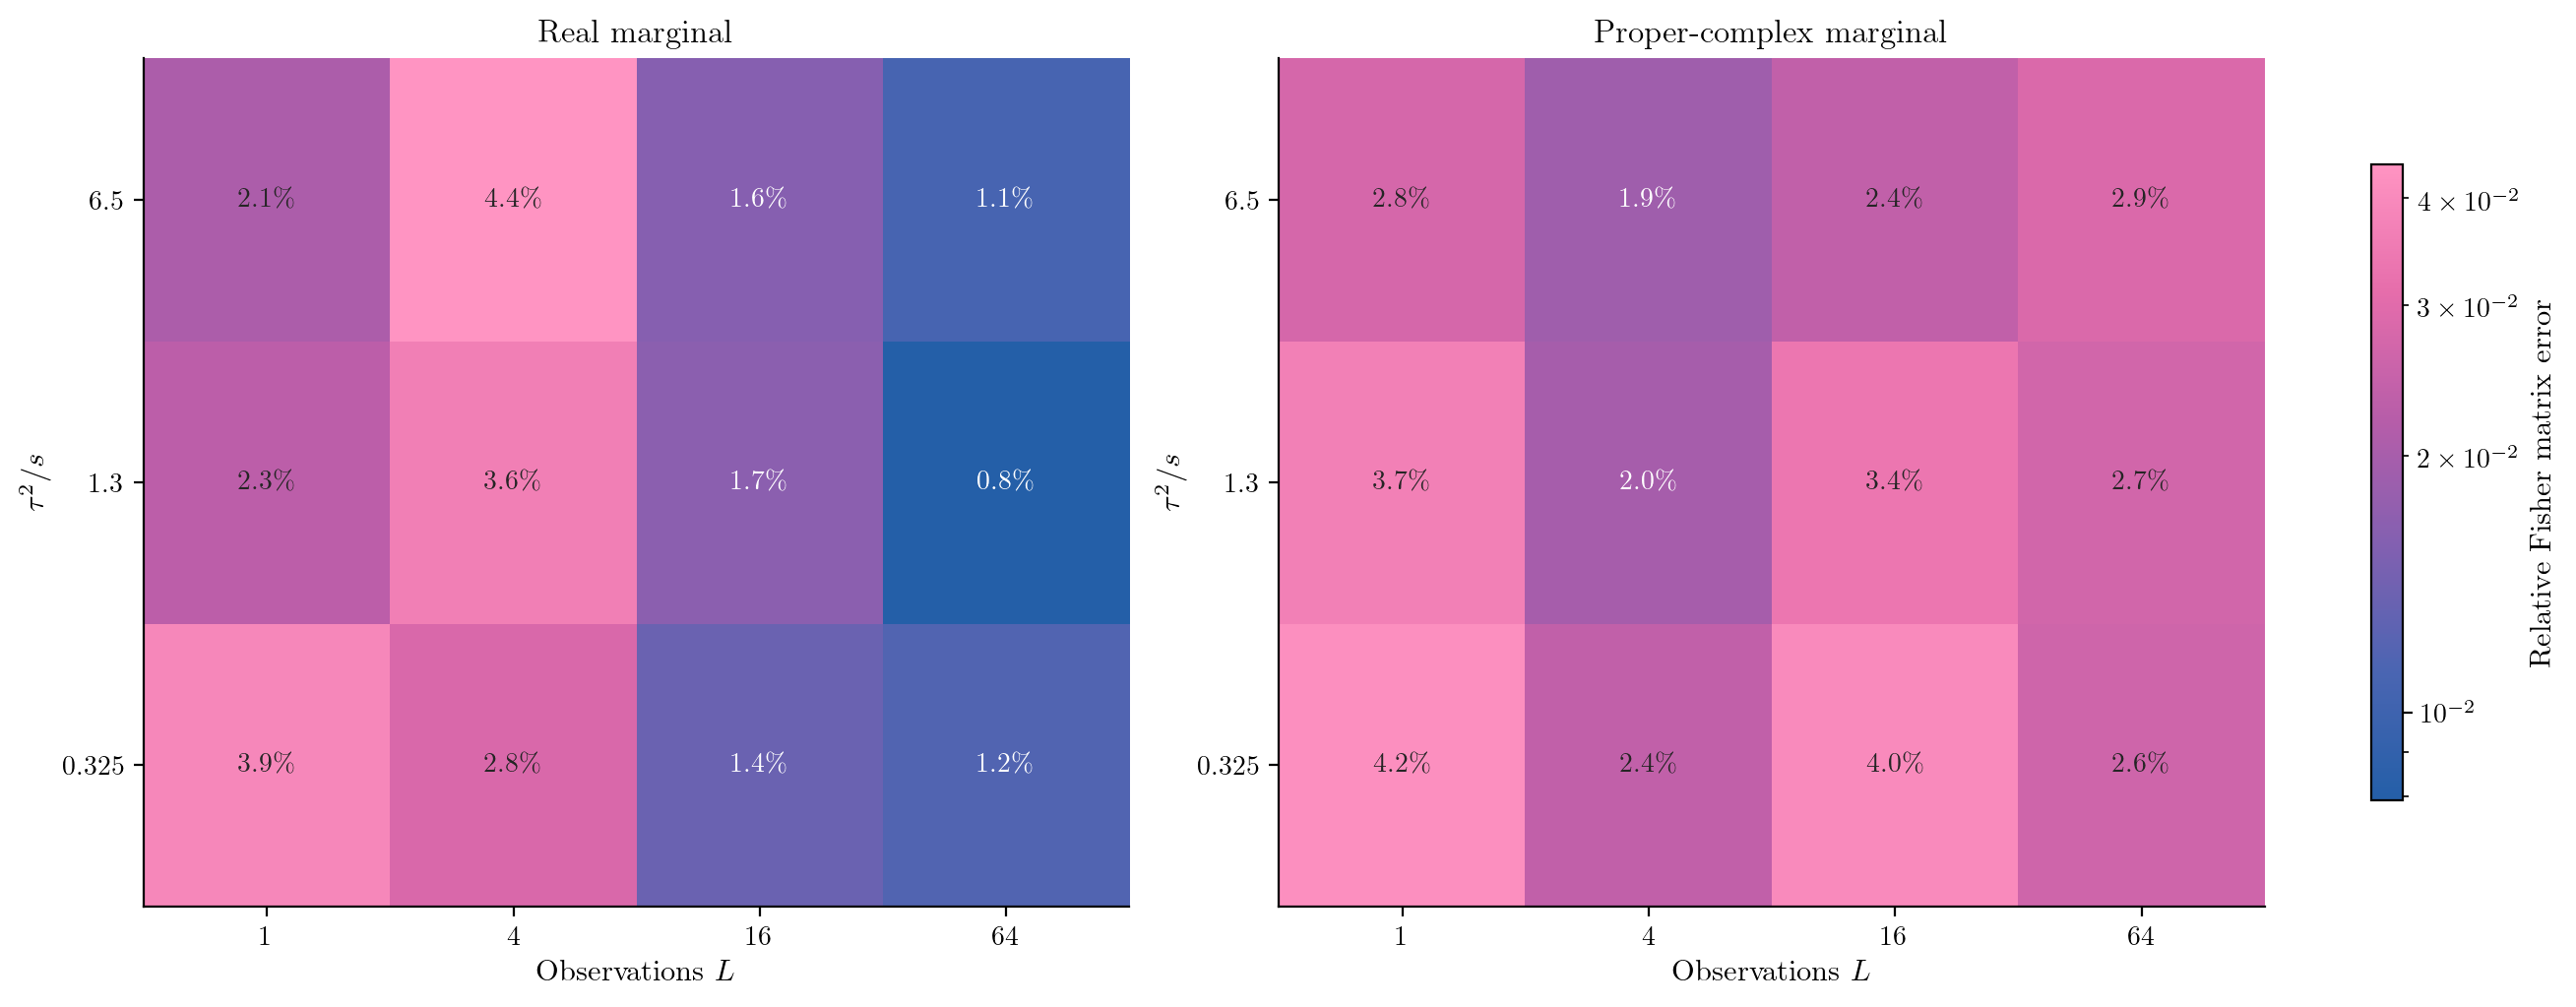

The observation-count and signal-to-noise axes correspond to a separate declared Fisher experiment. Score sums are formed inside each independent episode before estimating covariance across episodes. Common within-episode prefixes pair counts; coordinates are not independent repetitions. Cells report relative Frobenius Monte Carlo error of score information, with the independent episode count fixed across observation counts. The relative Monte Carlo error need not decrease as one over the square root of the observation count. Product-level checks remain in the tables.

In [4]:
show('B2a_count_error')

## B2b. Expected information is not realized posterior curvature

The marginal likelihood has isotropic expected information at its generating state. A finite collection of measured vectors can still produce unequal selected/complementary eigenvalue gaps. The realized negative Bingham log-density Hessian has twice those gaps in the real tangent chart. Flat directions after a small number of observations are retained.

The display fixes $N=3$ and the first declared sensor variance, then changes only the observation count. Boxes describe the spread of realized curvature eigenvalues across datasets, rather than uncertainty in a fitted regression coefficient. Posterior-mode and generating-state tangent frames are distinct, so this is an invariant spectral comparison.

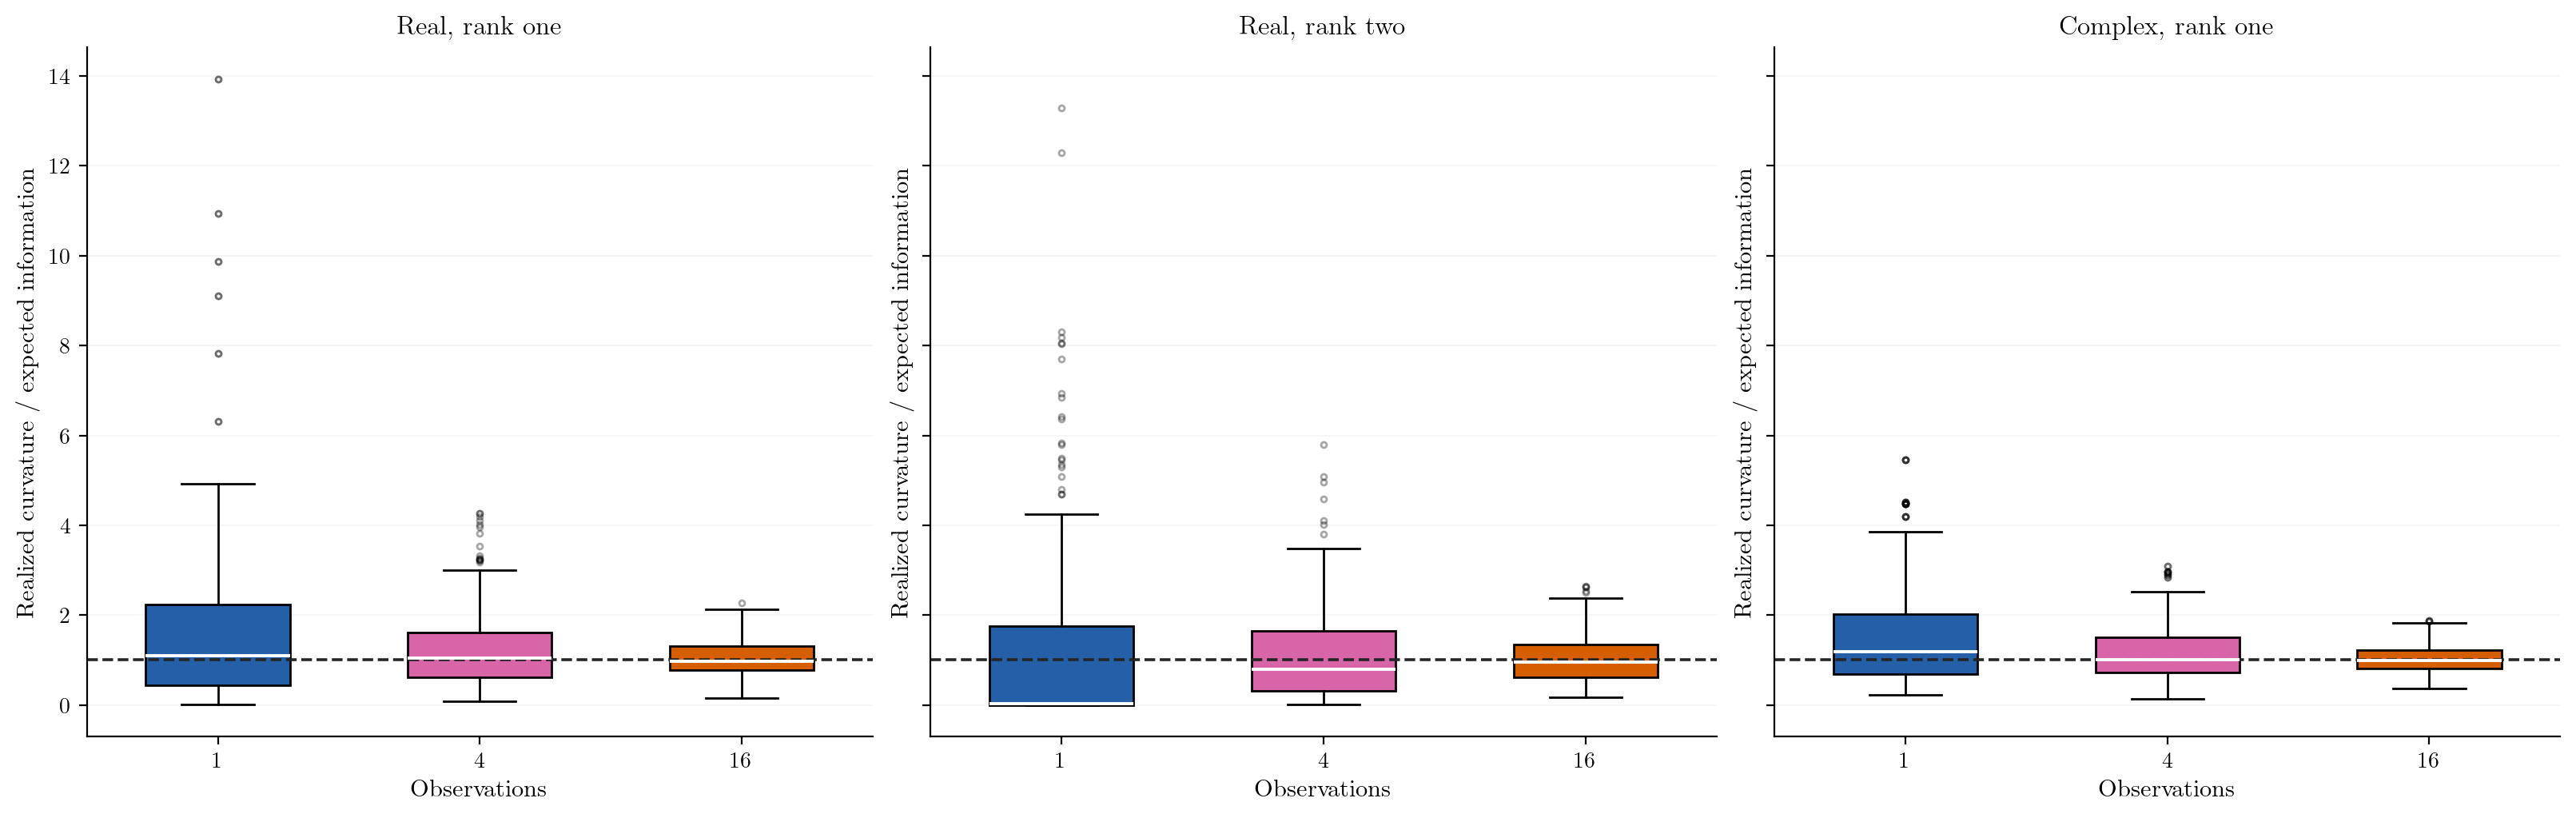

Boxes retain the distribution of realized curvature eigenvalues across independently generated datasets. Expected likelihood information is evaluated at the generating state; posterior curvature is evaluated at its own mode. A spectral comparison does not assert equality of those two tangent frames.

In [5]:
show('B2b_posterior_curvature')

## B3; C4. When does the modal tracking theorem say something?

For real marginal data, $\eta=\tau^2/[2s(s+\tau^2)]$, $h=N\log9+\log(2/\delta)$ and $\gamma_t=\eta\tau^2m_t$. The guide uses the fluctuation allowance $4\eta(s+\tau^2)(\sqrt{b_th}+h)$, with weighted aggregate drift and the initial spectral-gauge radius. The proper-complex extension changes both $\eta$ and $h$. Conditional bounds use their separate recorded-input formula.

The reported envelope is $2\sqrt{k}\epsilon_t/\gamma_t$ only when $\epsilon_t<\gamma_t/2$. A valid sufficient condition can still give an envelope above the geometric distance ceiling. These calculations use fixed true scales, deterministic paths and fixed memory; the true gap and drift are evaluation diagnostics, not an online confidence radius.

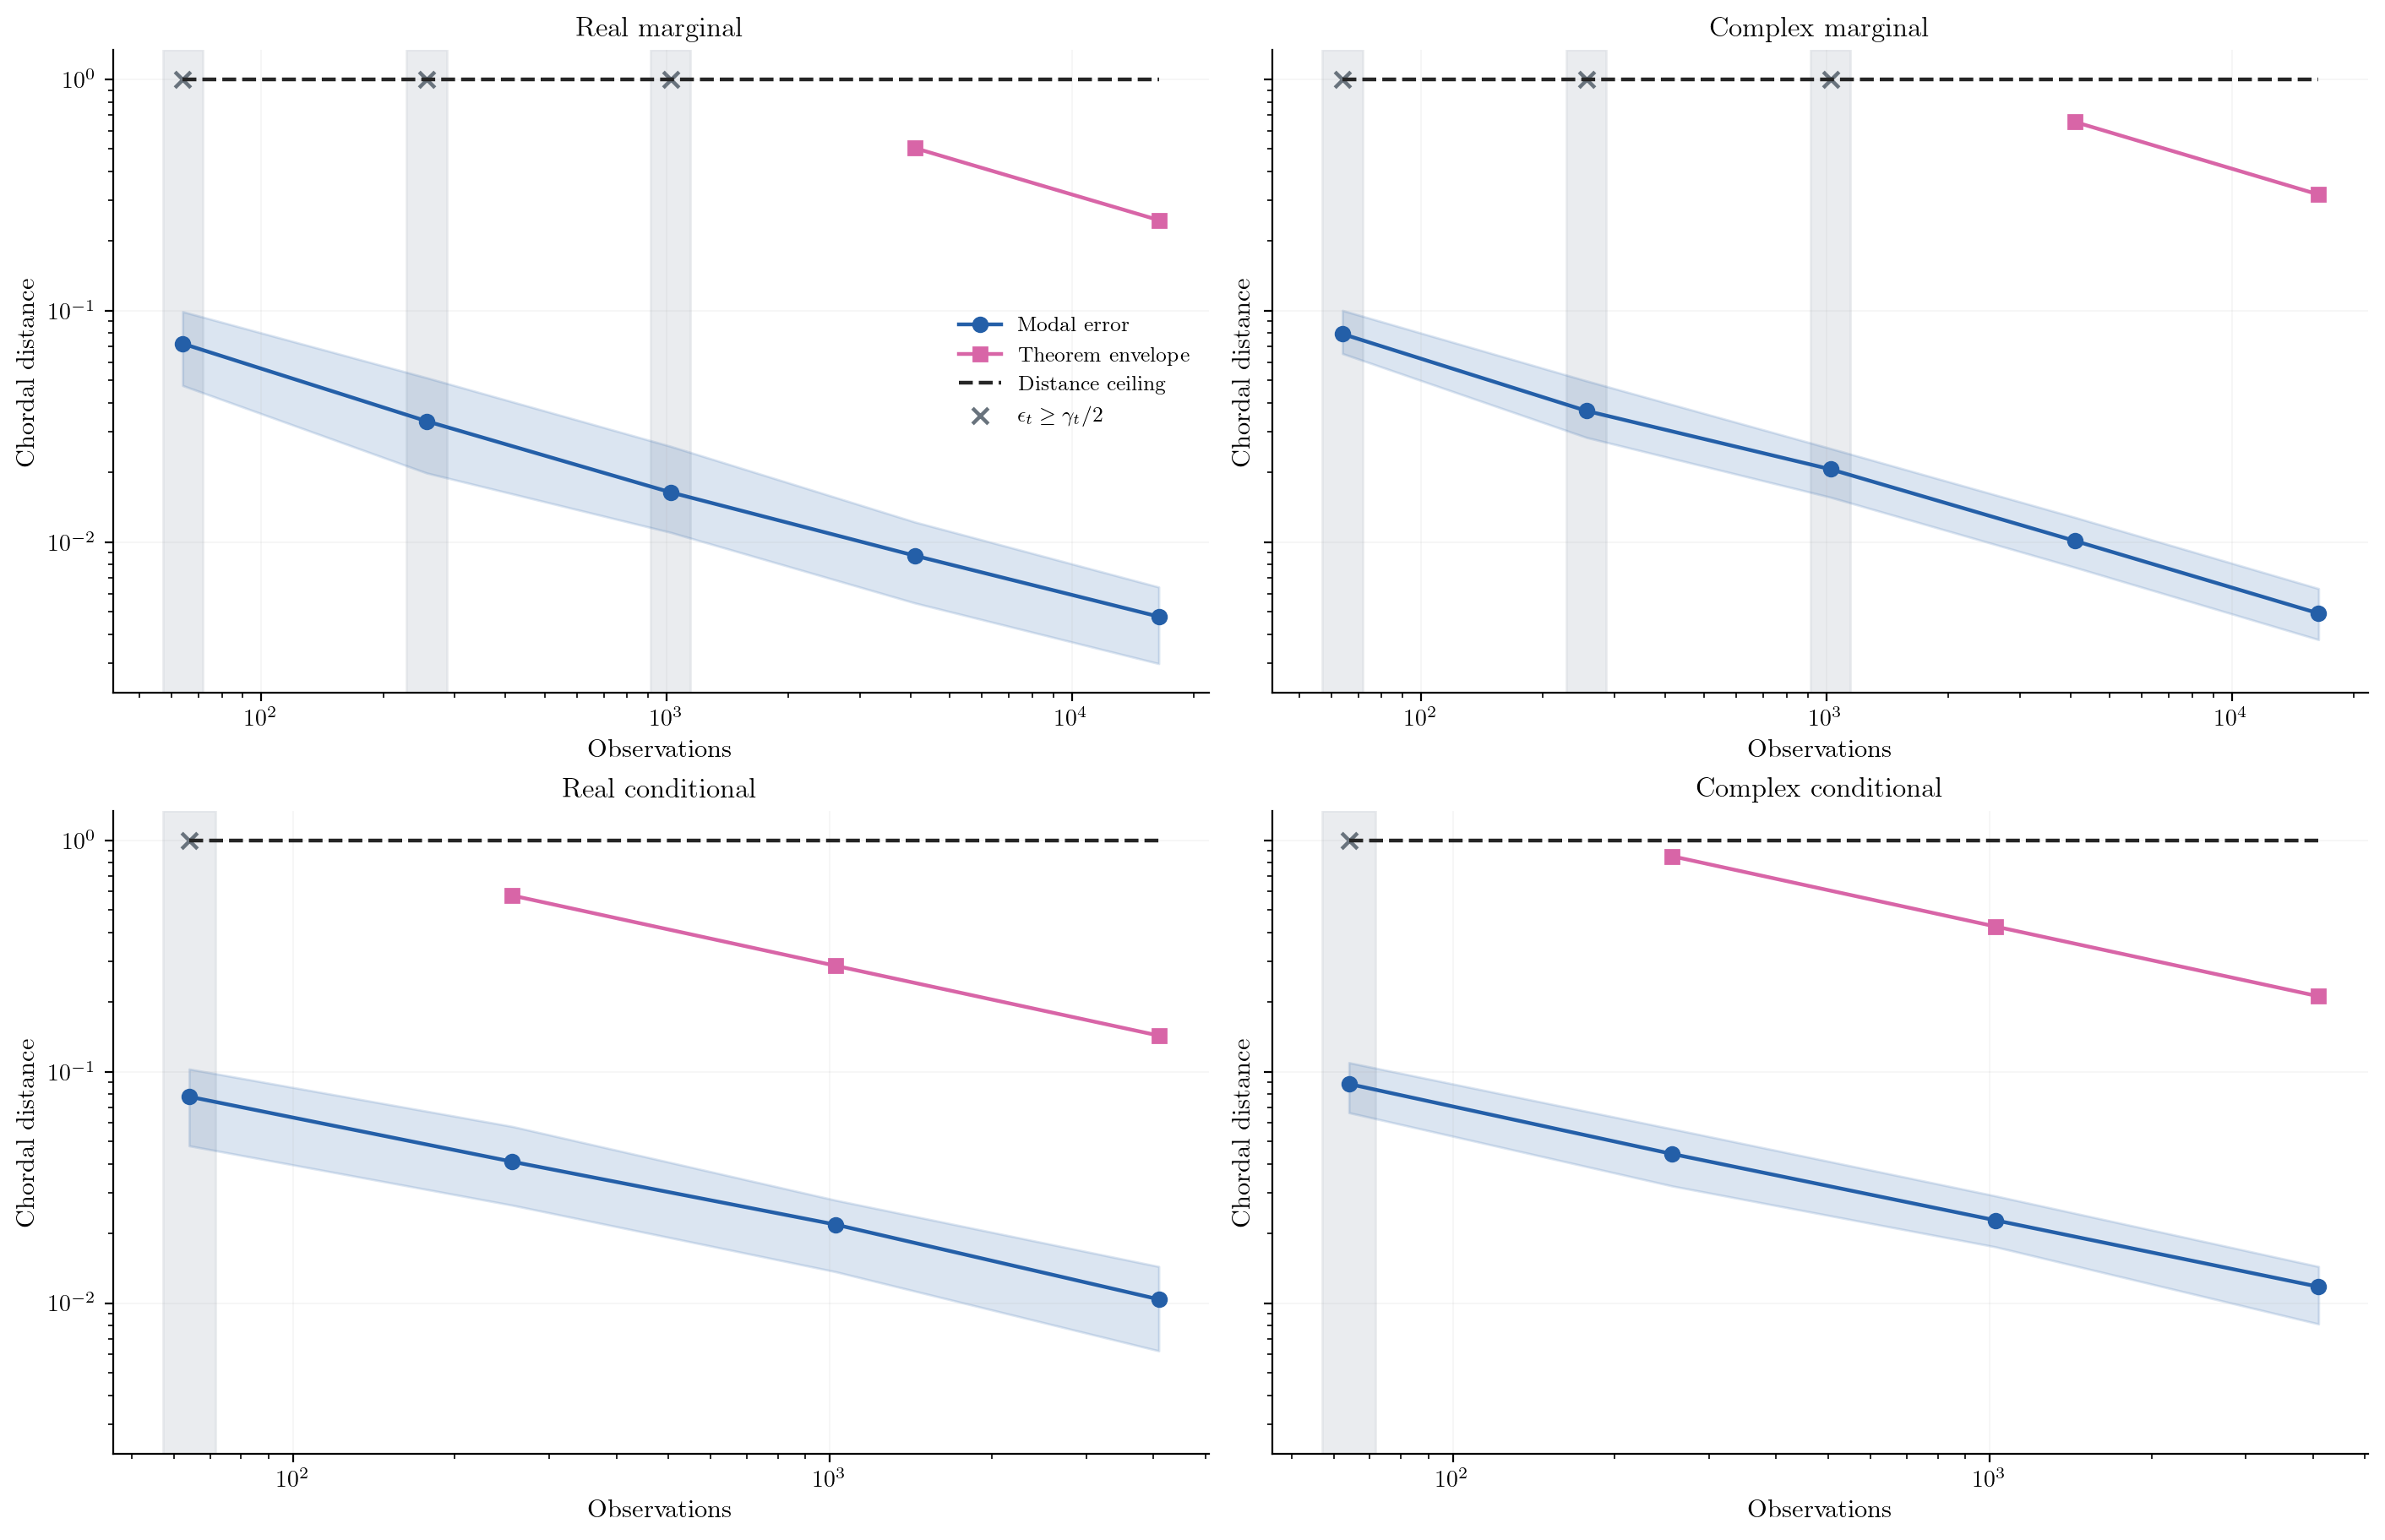

The fixed deterministic state path is repeated with independent signal and sensor noise. Blue bands are the interquartile spread of modal errors, not credible or confidence intervals. Gray bands and crosses mark reported checkpoints with insufficient gap conditions; the shading makes no claim about unreported times. The theorem envelope and geometric ceiling are different quantities; bounds use true fixed scales for evaluation.

In [6]:
show('B3_C4_modal_bounds')

## B3; C4. More time does not always fix a memory-limited bound

At $\beta<1$, the guide's stationary ratio has a positive limit:
$4(1+s/\tau^2)[\sqrt{h(1-\beta)/(1+\beta)}+h(1-\beta)]$.
If this limit is too large, increasing the horizon alone cannot make the sufficient condition informative. The phase diagram varies the declared drift and memory independently. Fixed-time violation counts, eligible episode counts and binomial intervals are kept separately; zero observed violations is not proof of a uniform-in-time guarantee.

In [7]:
from lib.guide_tracking import marginal_preflight
for beta in [1.0, 0.99]:
    check = marginal_preflight(n=3, s=0.2, tau2=1.0, t=16384, beta=beta)
    print('beta =', beta, ': epsilon/gamma =', round(check['ratio'], 3),
          '; gap condition =', check['valid'],
          '; permanently vacuous =', check['permanently_vacuous'])

beta = 1.0 : epsilon/gamma = 0.123 ; gap condition = True ; permanently vacuous = False
beta = 0.99 : epsilon/gamma = 1.584 ; gap condition = False ; permanently vacuous = True


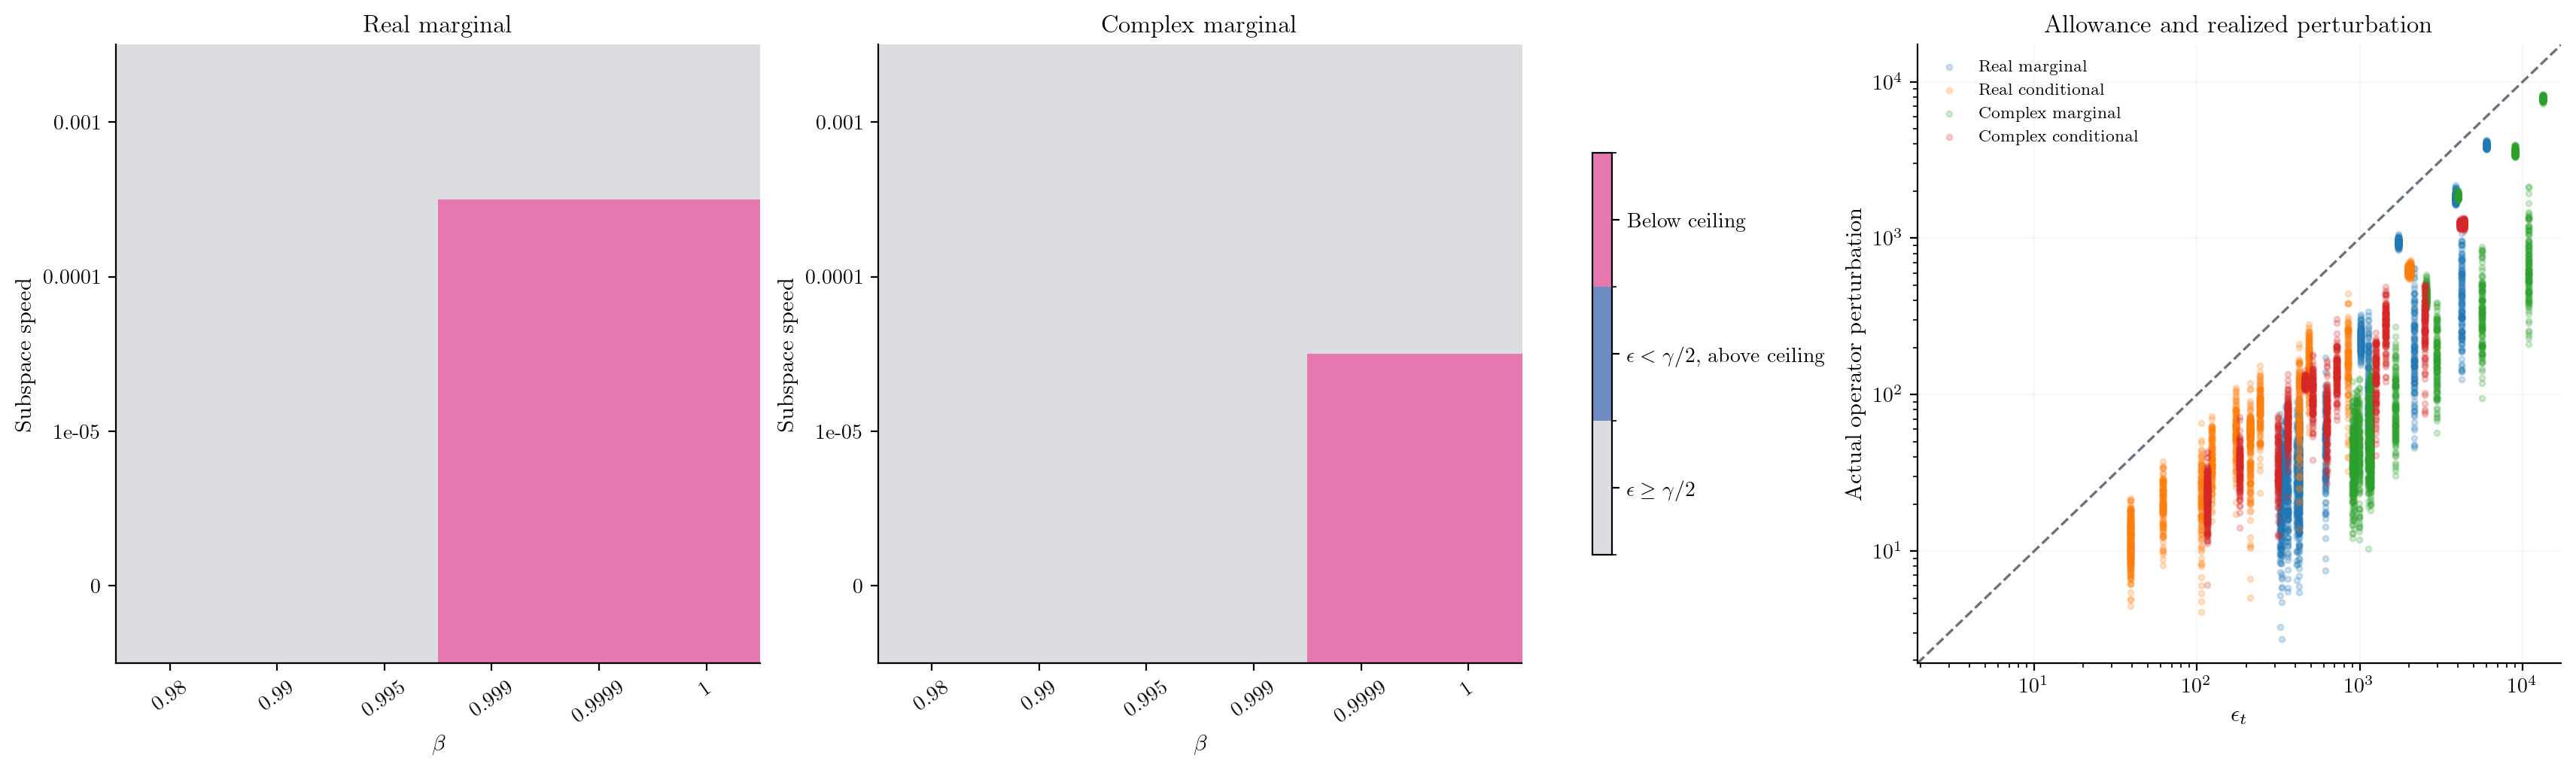

The phase diagram uses the predeclared largest horizon and smallest dimension. A sufficient gap condition can hold while the envelope remains above the geometric ceiling. Actual perturbations and theoretical allowances retain all trials. These truth-dependent diagnostics are not online confidence radii.

In [8]:
show('B3_C4_validity')

## B5. Compare decisions on fresh measurements

The posterior-mean covariance minimizes posterior expected output power under unit desired gain. It does not maximize expected SINR. The paired held-out measurements below are independent of training and shared by the competing decisions. A dot is one independent training episode, after averaging its held-out observations.

The matched-isotropy control and validation-loaded covariance remain in the full comparison tables. Matching modal overlap preserves trace and expected squared chordal loss, but does not preserve directional information. Matching a covariance alone also does not specify a predictive probability law.

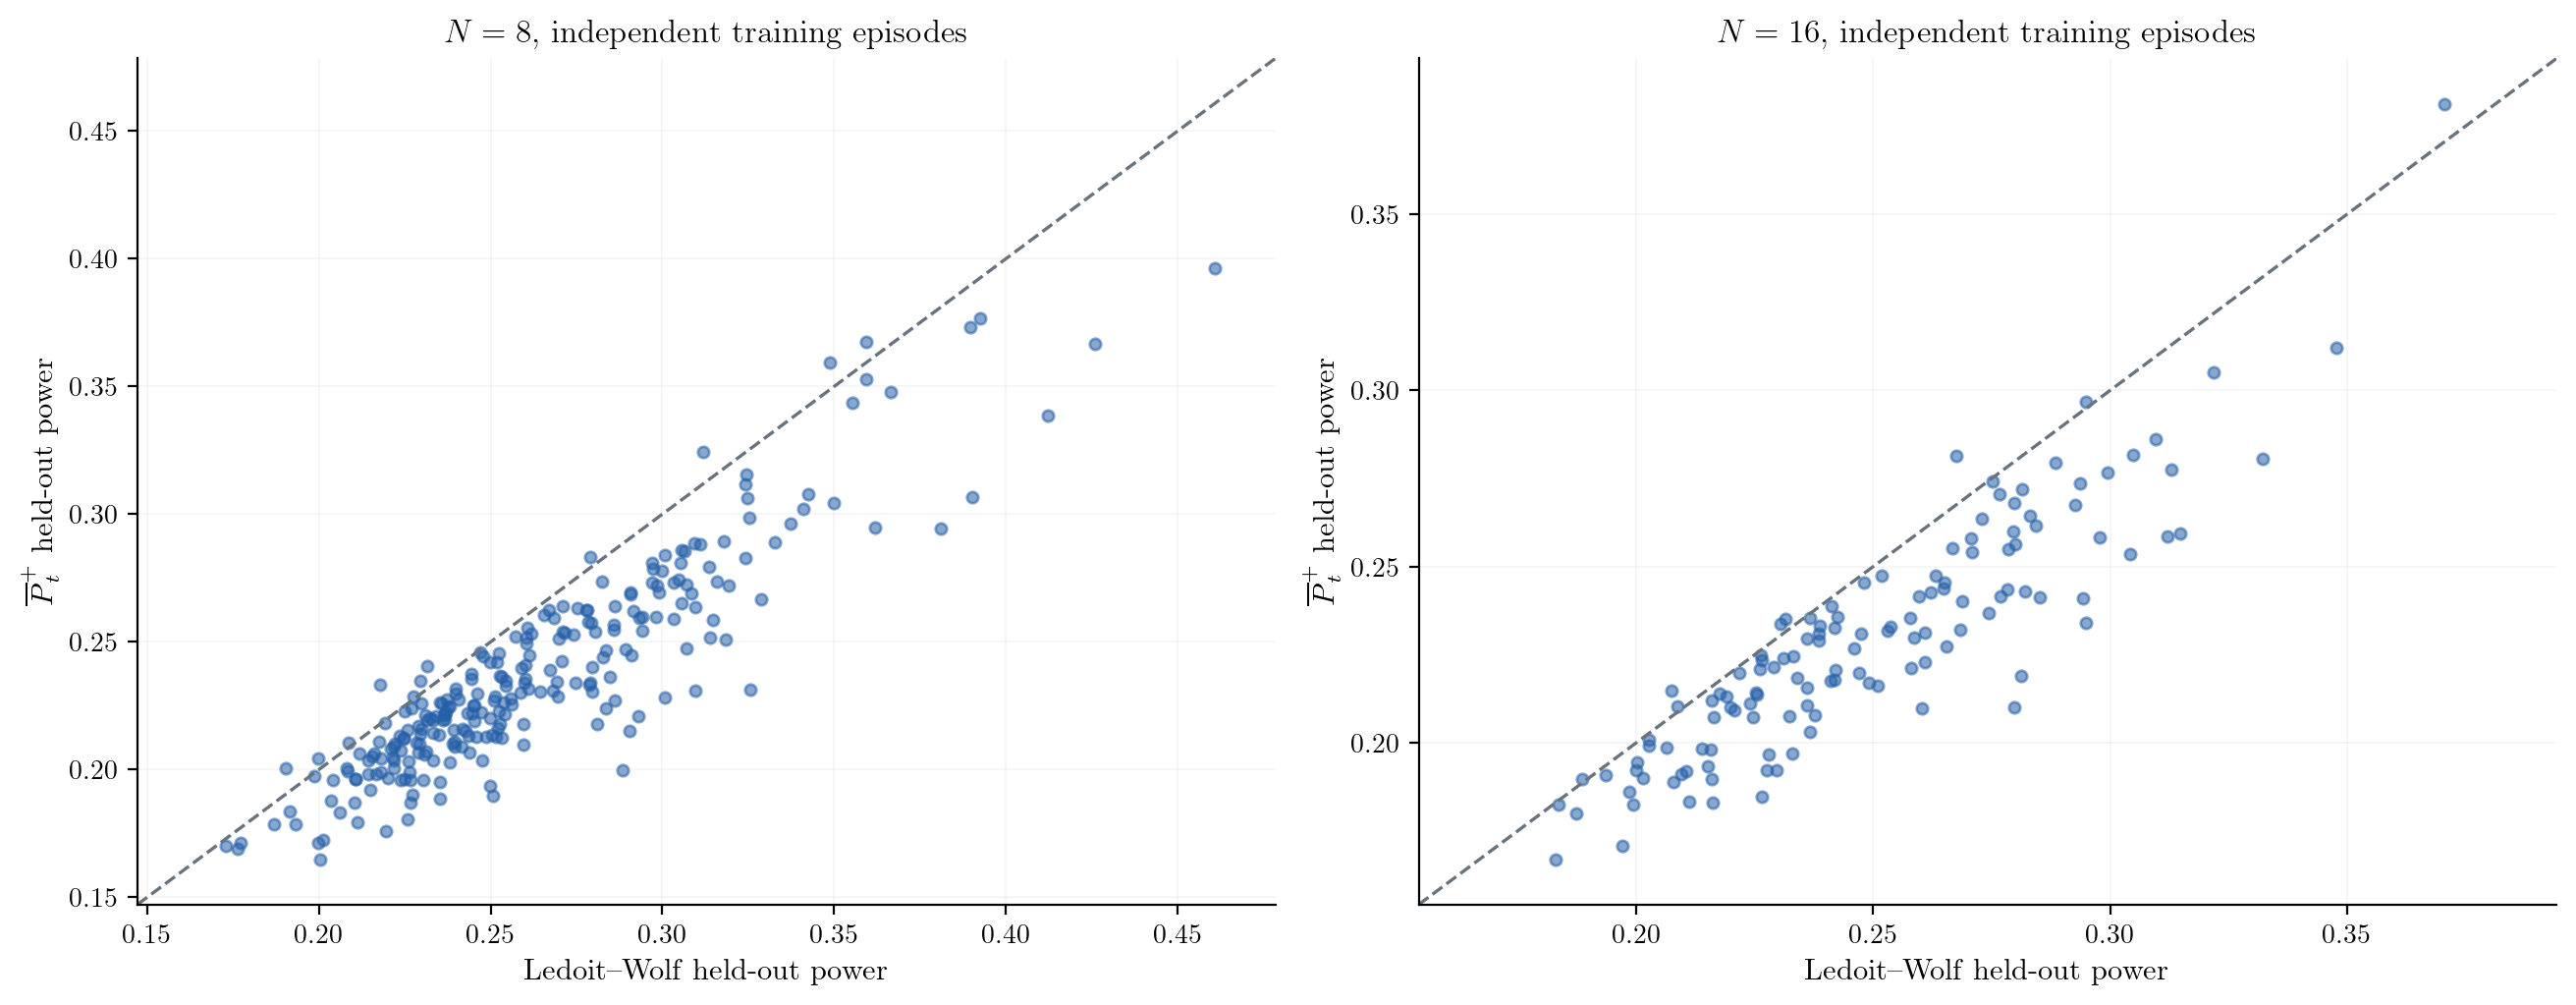

Each dot is one independent training episode at the preassigned Haar-signature setting, 16 snapshots and sensor variance 0.2. Both decisions are scored on exactly the same independent held-out snapshots. Below the diagonal favors the posterior mean. These observations complement the complete true-covariance and held-out paired tables; this display is not a universal ranking.

In [9]:
show('B5_heldout_decisions')

## B5. Keep changing motion, noise and power as separate interventions

The new tracking experiment uses snapshots alone and identity transport. It retains static, smoothly drifting and abruptly changing signatures, then changes sensor noise and interference power separately. The left panel compares a strong covariance decision with the posterior mean; the right holds the modal decision rule fixed while changing only its independently selected memory. A memory benefit is not an anisotropy benefit.

Every declared condition remains, including losses. Boxes contain independent paired episodes at the final prescribed checkpoint. The complete paired intervals and earlier checkpoints remain in the tables.

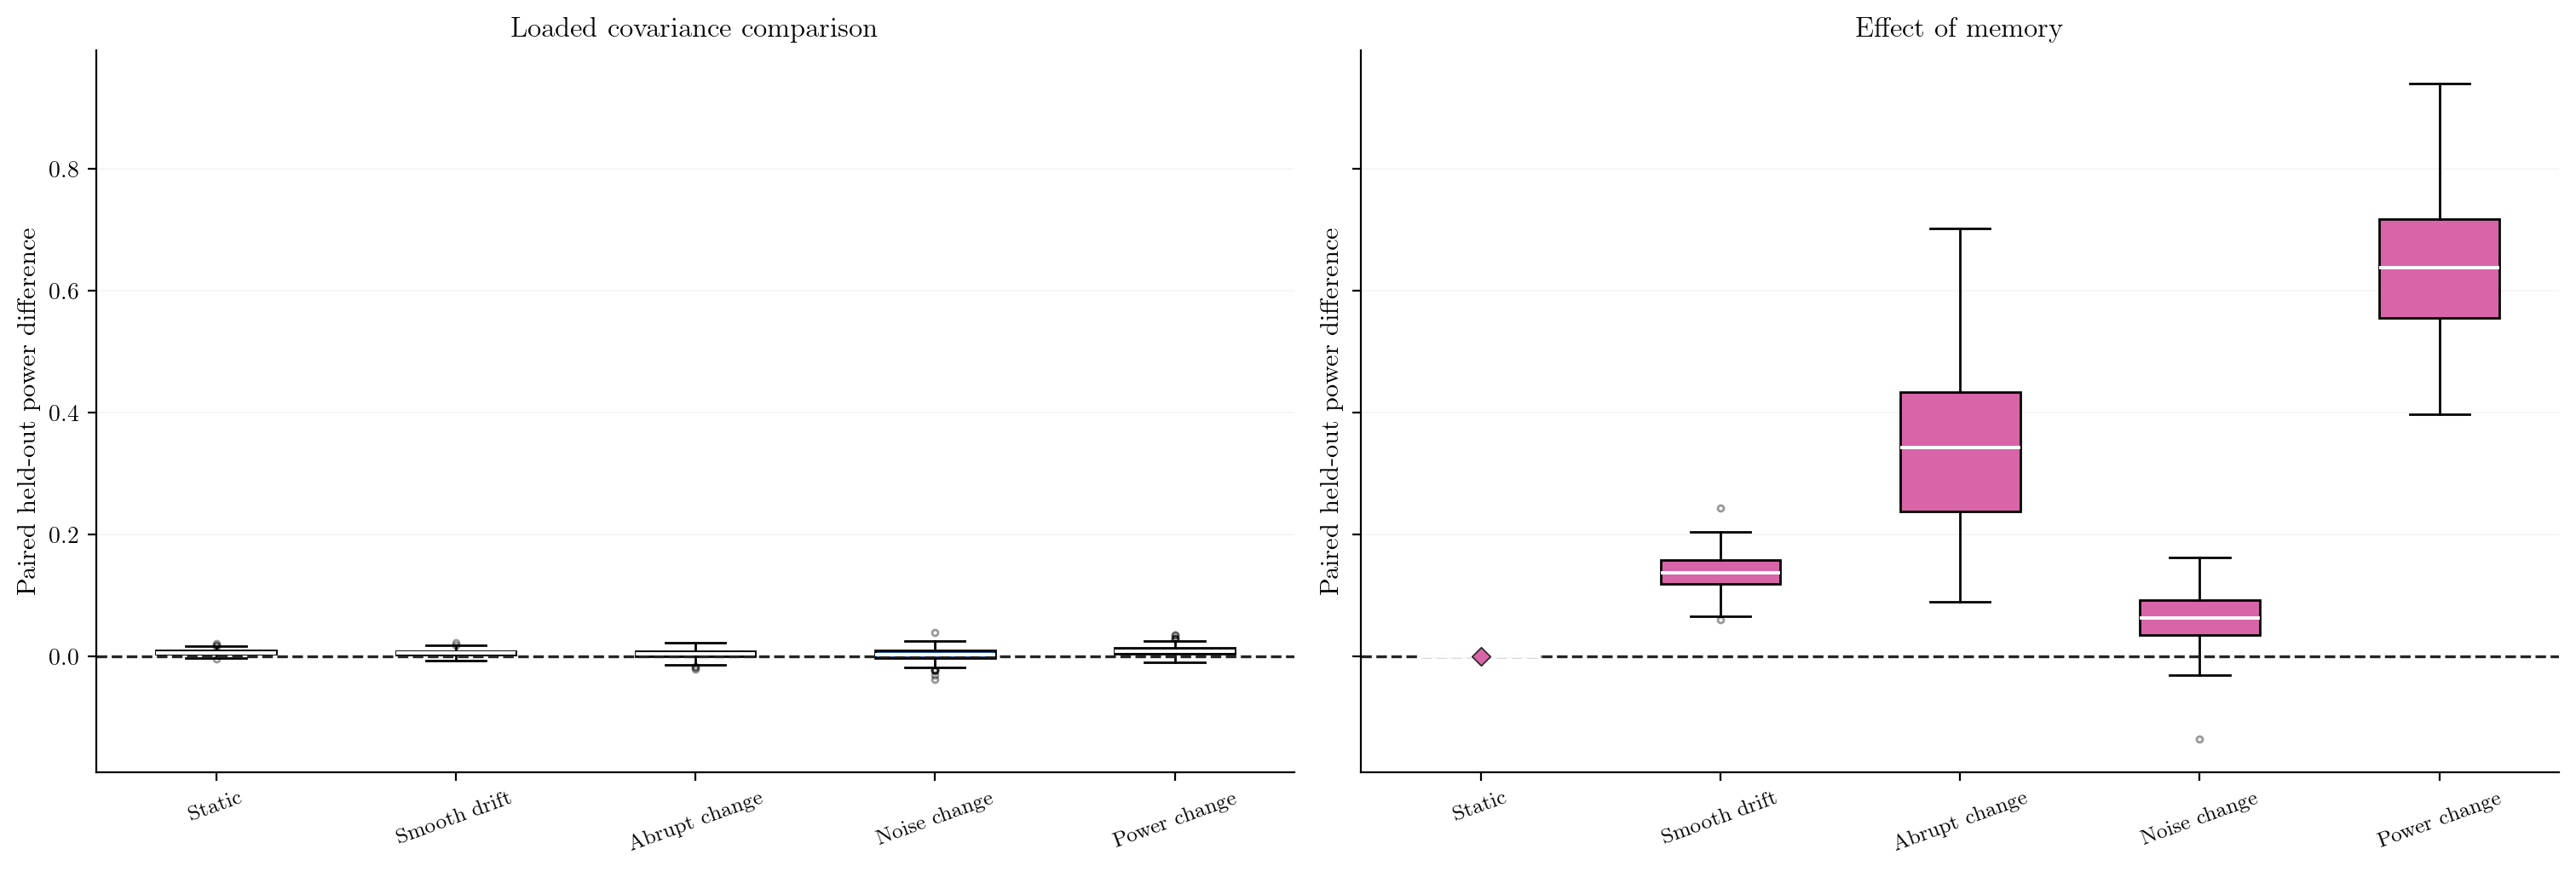

All five declared conditions are retained at the final reporting time. Each box contains paired independent test episodes. The left difference is loaded-covariance power minus posterior-mean power. The right difference is beta=1 modal power minus modal power with independently validation-selected fixed memory; the decision rule is held fixed there. Positive differences favor the second decision. No hidden input or oracle motion enters the tracker. Numerical flags and pointwise paired intervals remain in the tables.

In [10]:
show('B5_tracking_decisions')

## B6. State coverage, response risk and predictive density

Prior-predictive calibration first draws the state from the stated prior and then draws its data. Fixed-state and drifting-state repeated-data inclusion answer different questions. State regions, clean-response intervals and noisy predictive intervals are recorded separately, with episode-level uncertainty.

Scores are evaluated before assimilation from the full normalized singleton likelihood and the normalizer ratio. A Gaussian with covariance $sI+\tau^2\overline P$ matches a predictive second moment; it is a separate density from the projector mixture. Neither numerical accuracy of the mean nor a credible-mass identity guarantees fixed-state scalar coverage.

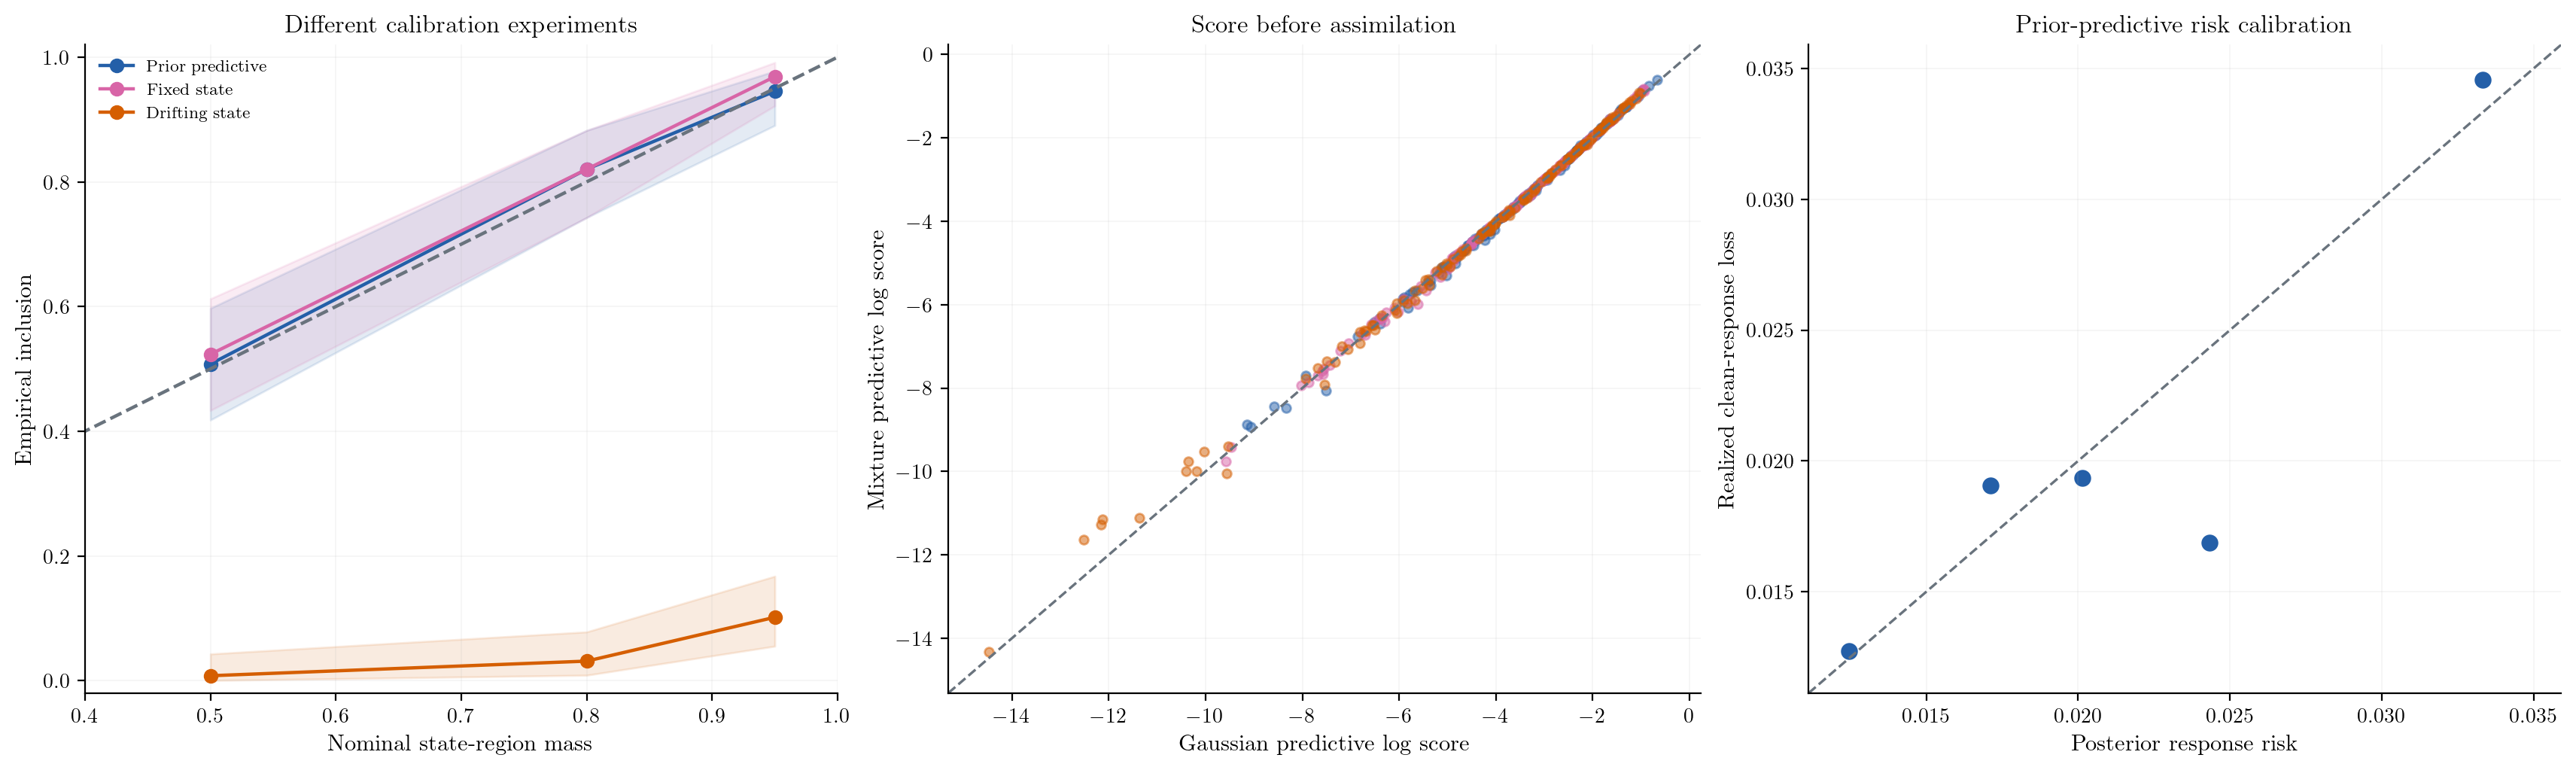

State inclusion uses independent episodes, with the saved pointwise binomial 95% intervals shaded. Prior-predictive, fixed-state and drifting experiments have different probability interpretations. Scores are computed before fitting or assimilation; the full normalized mixture and Gaussian moment surrogate are separate densities. Risk points average independent episodes in bins, and do not turn repeated time samples into extra trials.

In [11]:
show('B6_beam_calibration')

## C5. Apply the same probability distinctions to contact

The conditional model uses observed requests and directly measured instantaneous velocities with independent Gaussian sensor noise. Clean contact-response risk is evaluated on a fresh request. The calibration displays use the same conventions as beamforming, so observed differences can be traced to the observation model rather than a changed definition of coverage.

Every repeated-time quantity is averaged within an episode before comparing independent episodes. Validation-selected width adjustments and their independent test coverage remain in the tables; adjusting a width on test truth would invalidate that comparison.

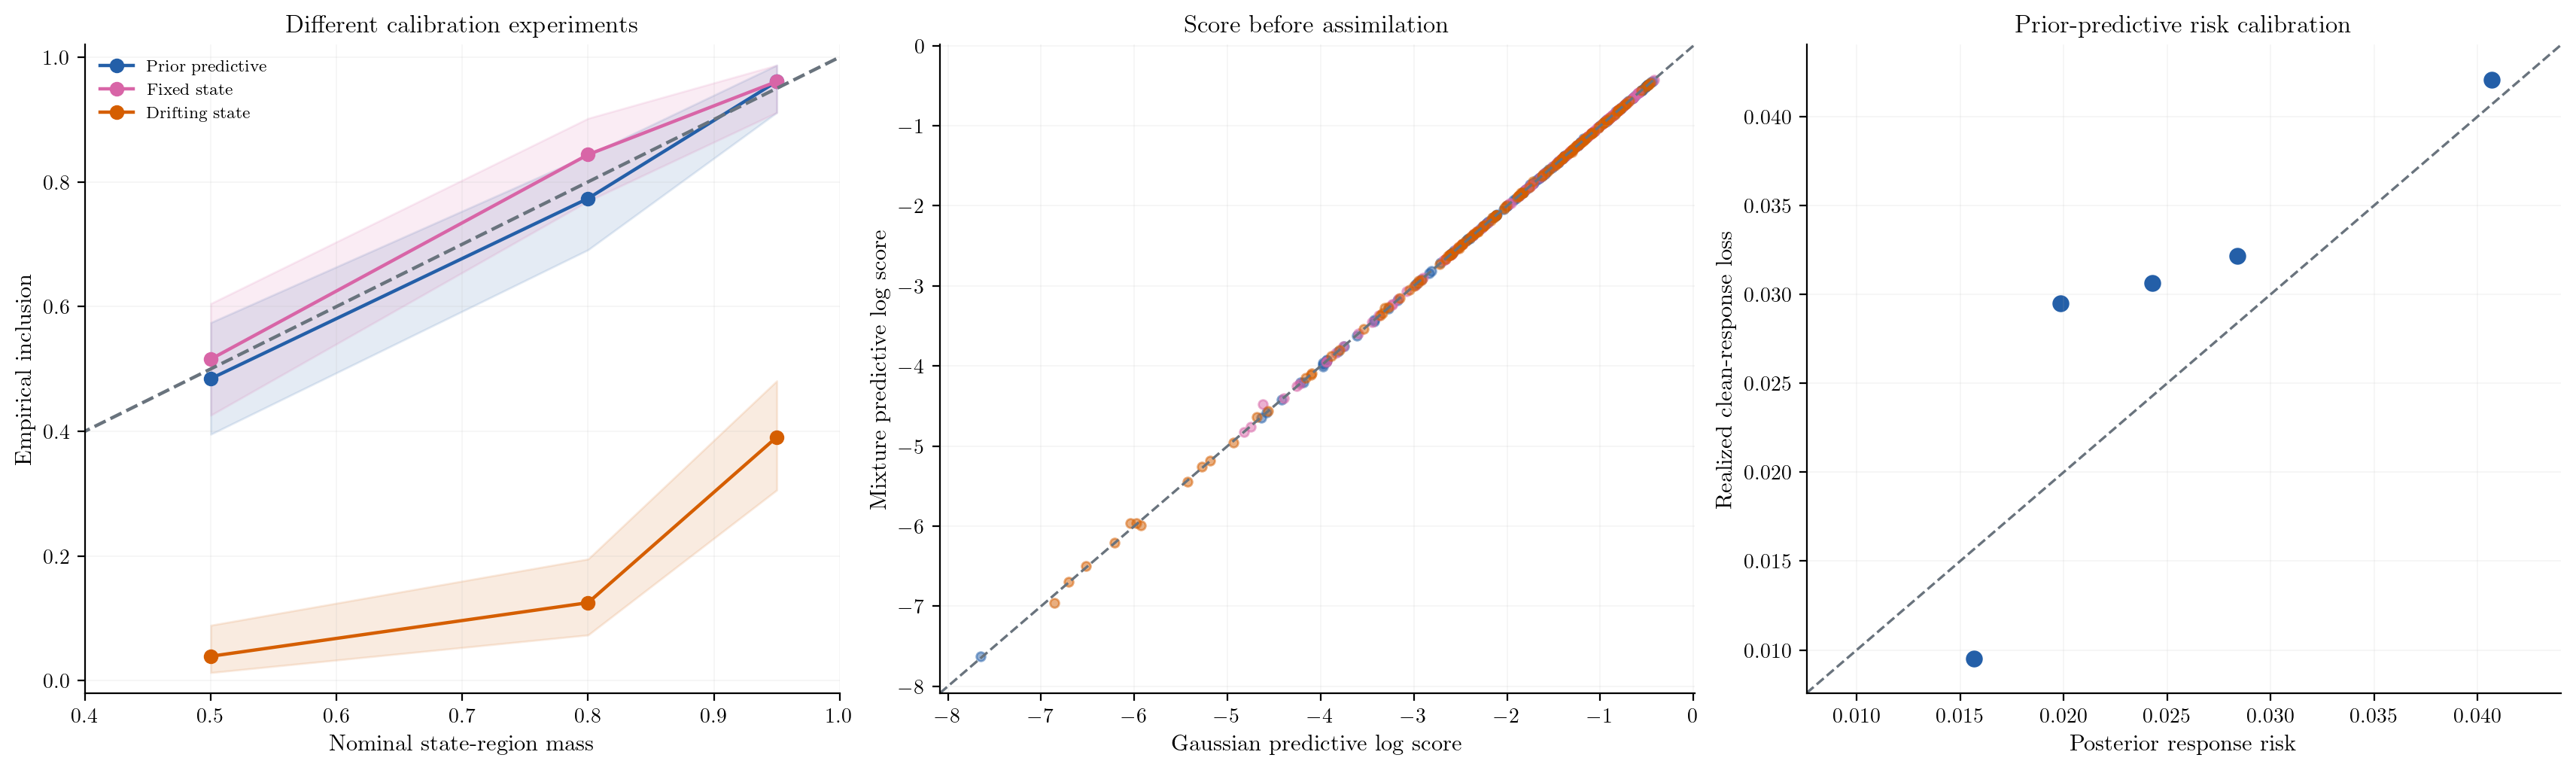

State inclusion uses independent episodes, with the saved pointwise binomial 95% intervals shaded. Clean-response intervals and noisy predictive intervals are distinct in the tables. Prior-predictive calibration does not imply fixed-state or drifting-state coverage. Mixture scores are evaluated before assimilation, and risk bins use episode averages.

In [12]:
show('C5_contact_calibration')

## B7a; C6a. Fit one stationary block under one boundary prior

The revised block EM objective assumes one constant subspace and a boundary prior excluding the entire block. Every E-step reconstructs $A_\partial+\sum_jB_j(\theta)$ from that same boundary. Full normalized evidence restores scalar likelihood terms and trace-gauge constants. This differs from the historical product under separately recorded single-observation priors.

Marginal updates respect ordered noise/signal variances. Conditional noise updates include posterior subspace uncertainty; replacing the projector by its mean inside a squared residual omits that term. Several positive interior starts are compared by normalized evidence. With a uniform prior, a zero signal-variance start can be absorbing and is kept as a declared boundary diagnostic.

Each displayed curve is shifted by its own initial evidence, so its final height does not rank starts. Start selection uses the absolute normalized evidence recorded in `fits.csv`.

The small block below illustrates the library API and trace gauge. It is a deterministic replay, separate from the independent Monte Carlo cohorts shown in the figure.

In [13]:
from lib.block_em import BlockData, block_posterior, fit_block_em
U = np.array([[1.0, 0.1, 0.0], [0.8, -0.1, 0.1], [1.1, 0.0, -0.1],
              [-0.9, 0.1, 0.1], [-1.2, -0.1, 0.0], [0.7, 0.0, 0.1]])
A_boundary = np.diag([0.3, -0.2, -0.1])
block = BlockData(U, k=1, boundary_prior=A_boundary)
shifted = BlockData(U, k=1, boundary_prior=A_boundary + 7 * np.eye(3))
post = block_posterior(block, s=0.2, tau2=1.0)
post_shifted = block_posterior(shifted, s=0.2, tau2=1.0)
assert np.allclose(post.mean, post_shifted.mean, atol=1e-9)
assert abs(post.log_evidence - post_shifted.log_evidence) < 1e-8
fit = fit_block_em(block, s=0.2, tau2=1.0, iterations=6)
assert np.min(np.diff(fit.objectives)) >= -1e-8
print('Gauge evidence error:', abs(post.log_evidence - post_shifted.log_evidence))
print('Accepted/rejected steps:', fit.accepted, '/', fit.rejected)
print('Block log-evidence increase:', fit.objectives[-1] - fit.objectives[0])

Gauge evidence error: 3.552713678800501e-15
Accepted/rejected steps: 6 / 0
Block log-evidence increase: 11.254307752970895


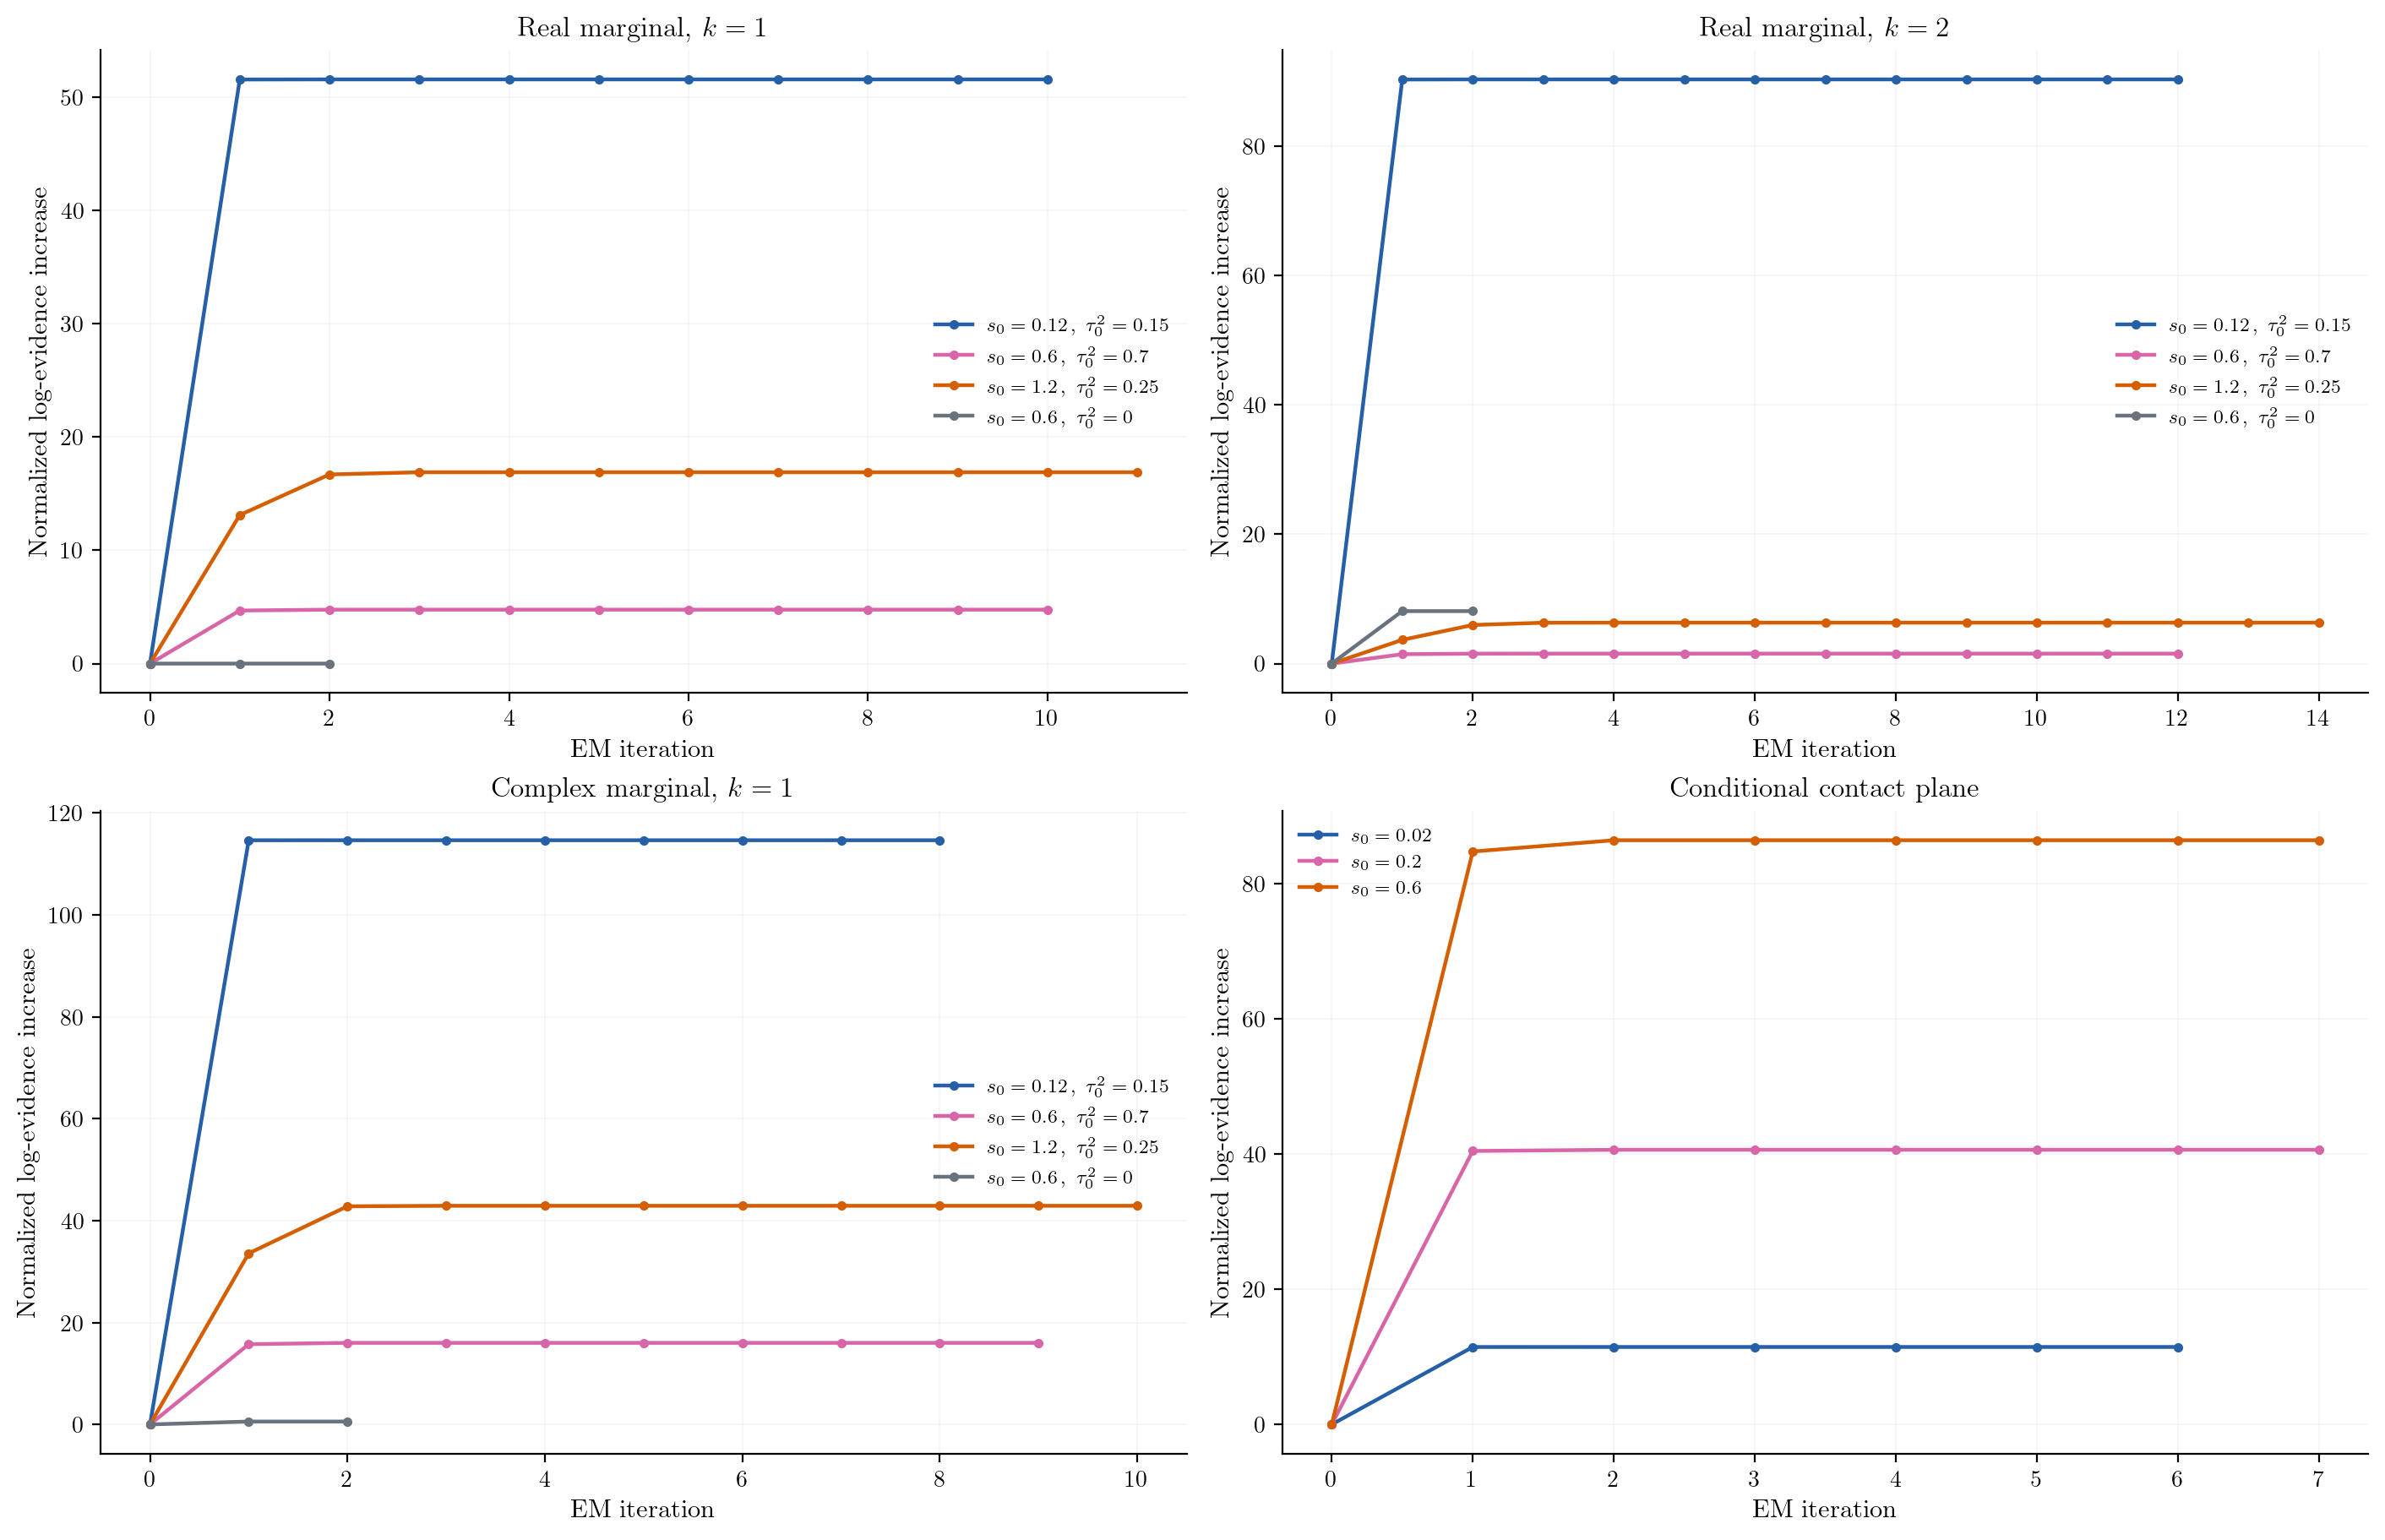

The displayed episode and starts are fixed before the test comparisons. Each E-step reconstructs the entire stationary block from one boundary prior excluding that block. Curves show the full normalized block evidence relative to its own initial value. A boundary signal-variance start can remain absorbing. Rejected updates and independent reference discrepancies remain in the tables.

In [14]:
show('B7a_C6a_block_evidence')

## B7b; C6b. Separate sensor changes from model changes

Evidence ascent for a fixed stationary block does not imply monotone online prediction scores, convergence under drift, or a learned forgetting factor. The next intervention changes sensor variance while holding motion fixed, then changes motion while holding sensor variance fixed.

Known scales use the generating variances. Misspecified scales keep $s=0.05$ and, for beamforming, $\tau^2=0.2$ fixed. Block EM rebuilds the fixed-boundary block objective, while residual fitting uses a modal point estimate and omits subspace uncertainty.

Inflation of a fitted noise parameter under motion mismatch does not establish recovery of physical sensor noise. Plug-in-scale intervals condition on those scales and omit their uncertainty. Adaptive runs are therefore separate from the fixed-scale theorem checks above.

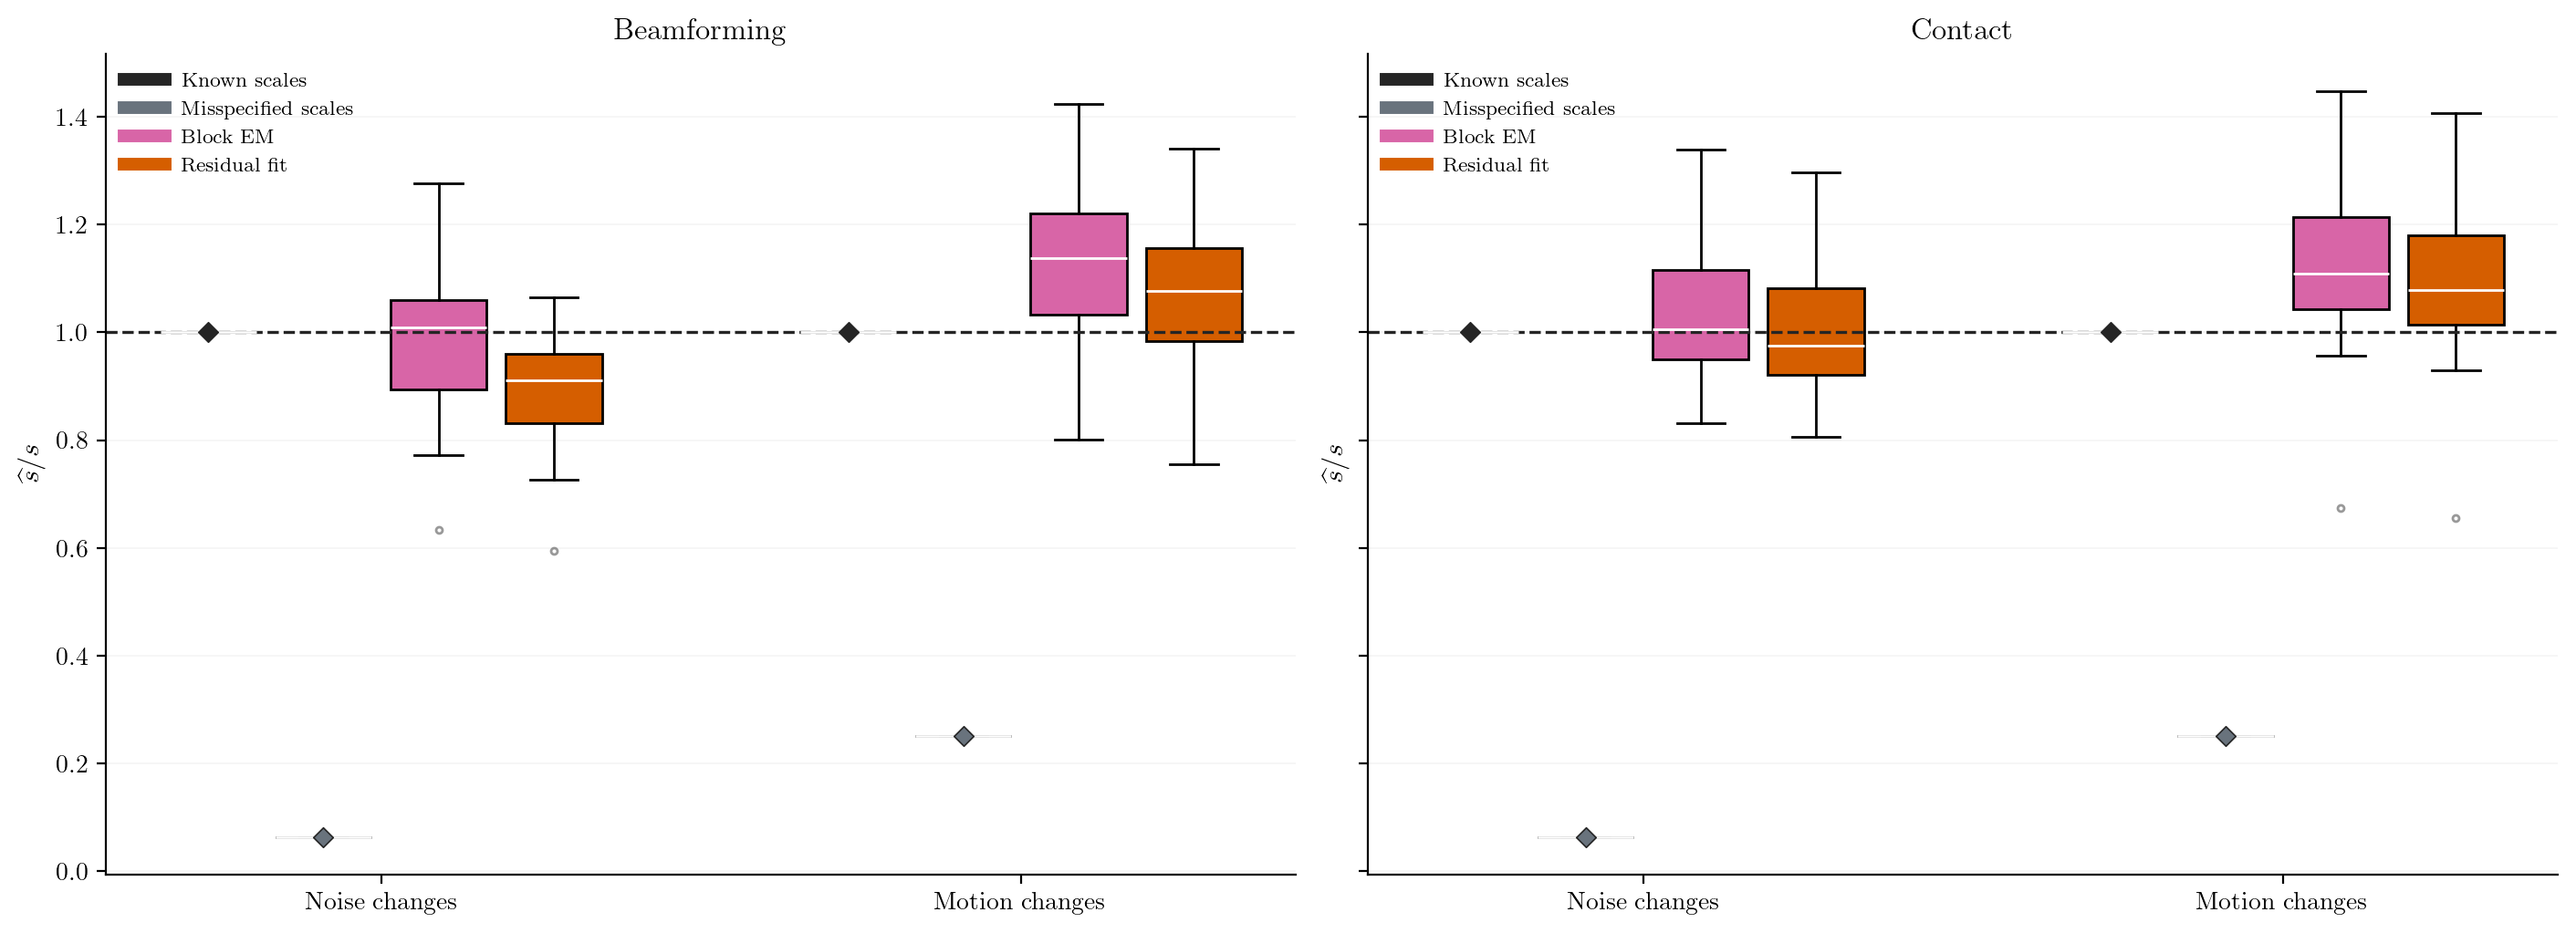

Separate noise-only and motion-only interventions use the final declared block. Box distributions contain independent episodes. The horizontal line is the true sensor variance. Motion-induced variance inflation is evidence of model mismatch, not recovery of a physical sensor parameter. Plug-in scale decisions omit scale uncertainty and do not inherit the fixed-scale tracking theorem.

In [15]:
show('B7b_C6b_scale_adaptation')

## C5. Keep changed mechanics and sensors visible

The ideal plant independently solves its KKT system. Maintained bilateral contact, known damping, negligible inertia and the noise model are assumptions of the conditional likelihood. Friction, detachment, anisotropic mobility and position-differenced velocity noise change that model.

Known anisotropic damping requires the scaled-coordinate projection and correctly transformed noise. Differencing independent noisy positions produces temporally correlated velocity errors. Those mechanical and covariance identities are checked directly; their mismatched counterparts remain diagnostic experiments, not claimed extensions of the isotropic theorem.

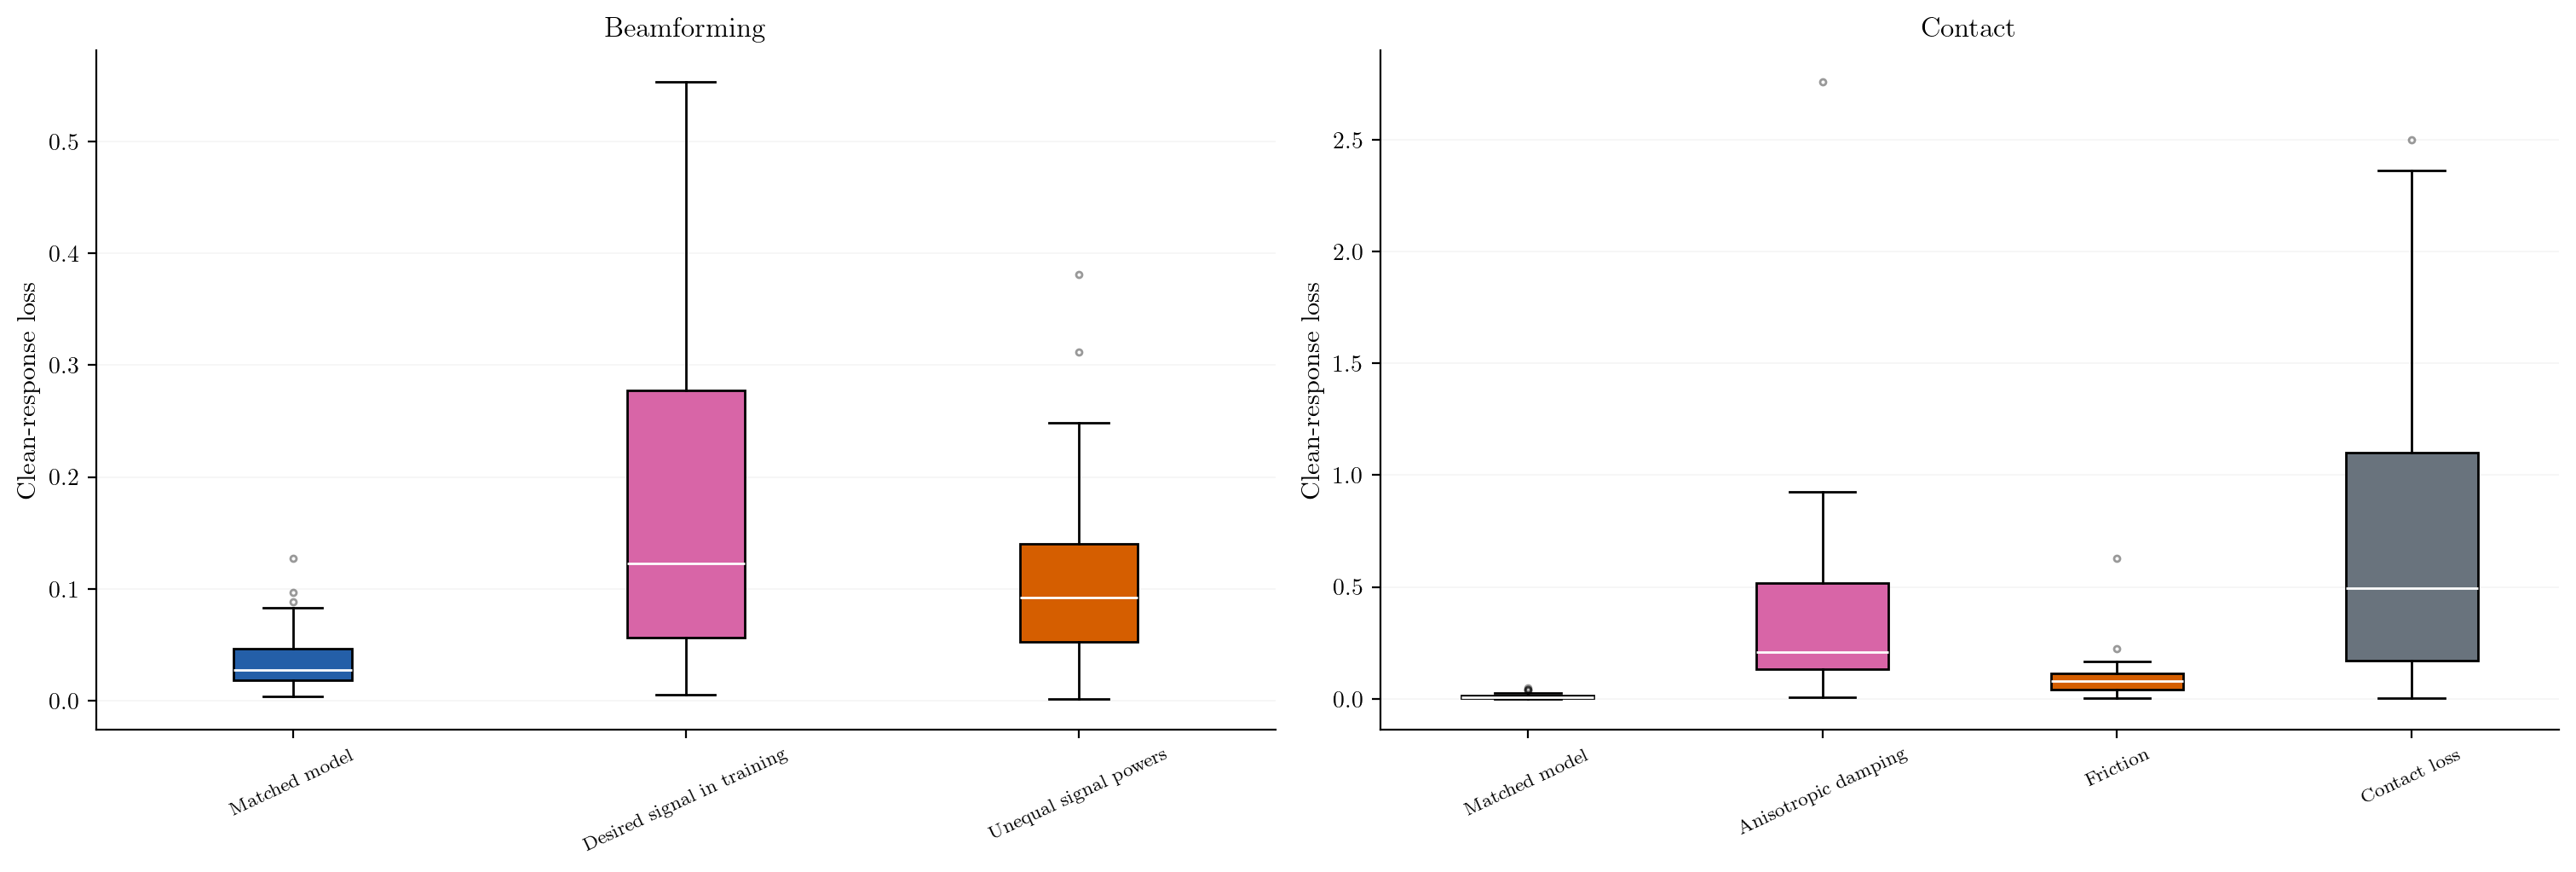

Each box contains episode-averaged clean-response loss. Friction, contact loss, anisotropic damping or correlated velocity errors are explicitly identified mismatch cases. They do not validate the isotropic independent-noise likelihood under changed physics. Correct scaled-coordinate mechanics and sensor covariance checks are recorded separately.

In [16]:
show('C5_model_mismatch')

## S1. Computational feasibility has a defined scope

The existing [scaling panels](../results/implementation_audit/paper/figures/S1_native_scaling.pdf) separate parameter corrections, eigenspaces, native moments and optional uncertainty reports. Native rank-one/codimension-one calculations do not validate arbitrary-rank integration. Serial timing runs have their own fixed streams, warm-up and repetition budget; reference-quality integration has separate accuracy settings.

The main applications and their raw results are retained. Read the [results note](../results/implementation_audit/findings.md), [claim manifest](../results/implementation_audit/claim_manifest.json), [audit protocol](../docs/implementation_guide_audit.md) and [reproduction commands](../results/implementation_audit/README.md) for numerical tolerances, Monte Carlo precision, limitations and the distinction between passed checks and inconclusive performance comparisons.